[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/10.%20Clustering%20Techniques/ch10_clustering.ipynb)

# Chapter 10: Clustering Techniques

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 10, pp. 276–301

**What you will learn in this chapter:**
- What unsupervised learning is and what *clustering* means (centroid-, connectivity- and density-based methods)
- How K-means works (assignment / update steps), how to choose *k* (elbow, silhouette) and why initialisation matters
- How agglomerative (hierarchical) clustering builds a dendrogram, and how linkage changes the result
- How DBSCAN finds arbitrarily shaped clusters and noise, and how to choose `eps` and `min_samples`
- How to evaluate clusterings with and without ground truth (silhouette, Davies-Bouldin, Adjusted Rand Index)
- How to choose among algorithms, and when spectral clustering and Gaussian mixture models help
- Practical exercises: K-means on Iris, DBSCAN vs K-means on moons, PCA + GMM on high-dimensional data

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Introduction to clustering | Group similar points without labels; the notion of distance is everything | `make_blobs`, `StandardScaler` |
| K-means | Alternate: assign points to the nearest centroid, move centroids to the cluster means | `KMeans`, `inertia_` |
| Hierarchical clustering | Merge the two closest clusters repeatedly; cut the tree at any height | `AgglomerativeClustering`, `linkage`, `dendrogram` |
| DBSCAN | Clusters = dense regions; sparse points are noise | `DBSCAN`, `NearestNeighbors` |
| Cluster evaluation | Internal (silhouette, Davies-Bouldin) vs external (ARI) metrics | `silhouette_score`, `davies_bouldin_score`, `adjusted_rand_score` |
| Choosing an algorithm | Match the algorithm to cluster shape, noise, size and dimension | — |
| Advanced clustering | Spectral clustering (graph-based), Gaussian mixtures (soft, probabilistic) | `SpectralClustering`, `GaussianMixture` |
| Practical exercises | Iris K-means, moons DBSCAN vs K-means, PCA + GMM | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers and figures printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged with **Book correction** (collected again at the end).
The book's snippets omit some imports; they are added here. The book never uses the true labels that `make_blobs`/`make_moons` return, but we do — *only* to score the clusterings (Adjusted Rand Index), never to fit them.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to clustering

**Summary.** *Supervised* models learn from inputs **and** outputs. In *unsupervised* learning there is no output to predict: we want to understand the structure of the data itself. **Clustering** groups similar data points together using only their features — customer segmentation, grouping documents, finding sub-populations before building a supervised model.
It is, as the book says, "more of an art than a science": the number of clusters, the notion of similarity and the algorithm all have to be chosen, and there is no ground truth to check against.

### Getting ready
Dummy data from `make_blobs`: 300 points around 4 centres, then standardised (z-scores) "to make our clusters easier to visualise".

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

In [3]:
X, _ = make_blobs(
    n_samples=300, centers=4,
    cluster_std=0.60, random_state=2024
)
X = StandardScaler().fit_transform(X)
print("X:", X.shape, "| mean:", X.mean(axis=0).round(3), "| std:", X.std(axis=0).round(3))

X: (300, 2) | mean: [0. 0.] | std: [1. 1.]


### How to do it…

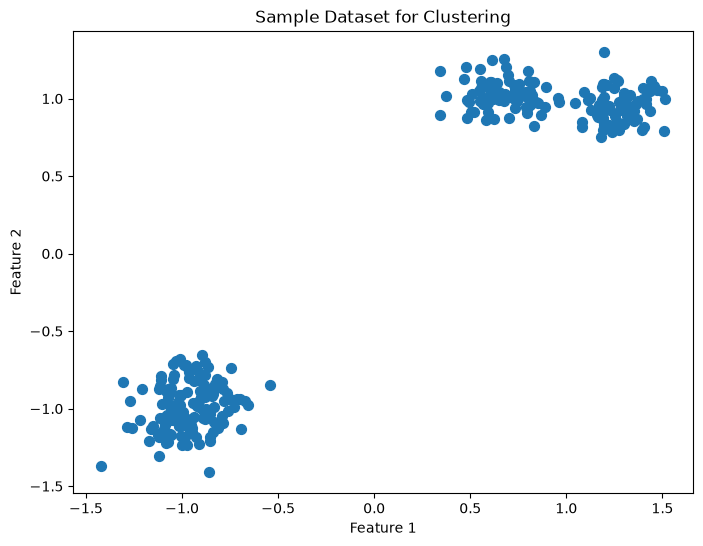

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Sample Dataset for Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Verification against the book:** Figure 10.1 — the same scatter plot. Look at it carefully: although 4 centres were requested, the points form **two obvious groups, each made of two touching blobs** (the true centres are approximately (1.8, 4.0), (4.6, 3.6) and (−6.3, −9.2), (−5.9, −7.9) before scaling). Remember this when we choose *k* in Section 2.

### How it works…
Clustering computes the similarity between points from **distances** (or densities). The book distinguishes three families:
* **Centroid-based** — clusters formed around a central point (K-means);
* **Connectivity-based** — clusters built from hierarchical links (agglomerative clustering);
* **Density-based** — dense regions separated by sparse ones, with noise (DBSCAN).

**Extension — why scaling matters for every distance-based method.** Multiply one feature by 100 (a change of units, e.g. metres → centimetres) and K-means is dominated by that feature. Adjusted Rand Index (ARI) scores agreement with the true blobs (1 = perfect, ≈ 0 = random):

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

X_raw, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
X_units = X_raw * np.array([1, 100])                       # feature 2 expressed in 100x smaller units
for name, data in [("original features", X_raw), ("feature 2 x 100, unscaled", X_units),
                   ("feature 2 x 100, standardised", StandardScaler().fit_transform(X_units))]:
    labels = KMeans(n_clusters=4, random_state=2024).fit_predict(data)
    print(f"{name:32s} ARI = {adjusted_rand_score(y_true, labels):.3f}")

original features                ARI = 0.814
feature 2 x 100, unscaled        ARI = 0.496
feature 2 x 100, standardised    ARI = 0.801


Changing only the *units* of one feature drops the ARI from 0.81 to **0.50**: the large-valued feature dominates every Euclidean distance, so K-means effectively clusters on one axis. Standardising restores it (0.80 — not exactly 0.81 because z-scoring slightly changes the geometry).

### Theory — what clustering needs
* **A similarity (distance) measure** — Euclidean distance by default; standardise features of different scales first, and reduce dimension for very high-dimensional data (Section 6).
* **An algorithm with an inductive bias:** K-means prefers round, similar-sized clusters; hierarchical clustering builds a nested family; DBSCAN looks for dense regions of any shape.
* **No labels, so evaluation is indirect:** internal metrics (silhouette, Davies-Bouldin) measure geometry; external metrics (ARI) need ground truth that real projects rarely have (Section 5).

### Hands-on workflow (book)
Generate or load an unlabelled dataset, visualise it, apply `KMeans`, `AgglomerativeClustering` and `DBSCAN`, visualise the resulting clusters and experiment with parameters — done in the sections that follow, and in the practical exercises.

## 2. K-means clustering

**Summary.** K-means partitions the data into a **predefined number *k*** of clusters. It starts with *k* centroids, repeatedly assigns each point to its nearest centroid and then moves each centroid to the mean of its points, until the assignments stop changing. It is fast and works best when clusters are **convex, isotropic and of similar size** — "which also can be its greatest weakness".

### Getting ready
Reuse the scaled dataset `X` from Section 1.

In [6]:
from sklearn.cluster import KMeans

### How to do it…
`n_clusters` (the *k*) is the only required argument.

In [7]:
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

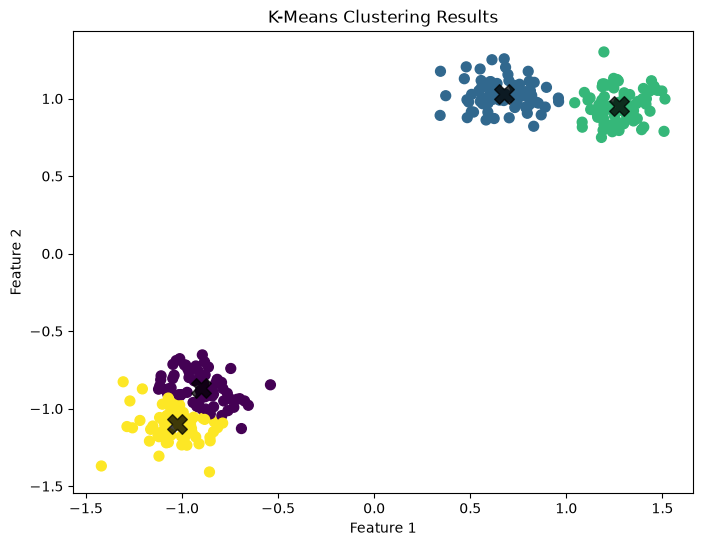

cluster sizes: [71 77 73 79] | inertia: 7.295 | iterations: 4
ARI vs the 4 true blobs: 0.801


In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X[:, 0], X[:, 1],
    c=y_kmeans, s=50, cmap='viridis'
)
centers = kmeans.cluster_centers_
plt.scatter(
    centers[:, 0], centers[:, 1],
    c='black', s=200, alpha=0.75, marker='X'
)
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("cluster sizes:", np.bincount(y_kmeans), "| inertia:", round(kmeans.inertia_, 3), "| iterations:", kmeans.n_iter_)
print("ARI vs the 4 true blobs:", round(adjusted_rand_score(y_true, y_kmeans), 3))

**Verification against the book:** Figure 10.2 — four colour-coded clusters with black X centroids ✔ (sizes 71 / 77 / 73 / 79 against 75 true points per blob; two of the four clusters are slightly "cut" because neighbouring blobs touch).

### How it works…
The book's three steps: **initialisation** (random centroids, or the smarter K-means++), **assignment** (each point to the nearest centroid, Euclidean distance) and **update** (each centroid becomes the mean of its points), repeated until convergence or `max_iter`. K-means minimises the within-cluster sum of squares (**inertia**). Both claims can be checked directly.

**Extension — Lloyd's algorithm by hand.** Start from four fixed points and run assign/update until nothing changes; scikit-learn started from the same centroids with `tol=0` must end at exactly the same place, and `inertia_` is just the sum of squared distances to the assigned centroid:

In [9]:
def lloyd(X, centers):
    for it in range(1, 301):
        d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)       # assignment step
        labels = d2.argmin(axis=1)
        new = np.array([X[labels == k].mean(axis=0) for k in range(len(centers))])   # update step
        if np.allclose(new, centers, atol=0, rtol=0):
            break
        centers = new
    return labels, centers, it

init = X[np.random.RandomState(0).choice(len(X), 4, replace=False)]
labels_h, centers_h, n_it = lloyd(X, init)
km_ref = KMeans(n_clusters=4, init=init, n_init=1, tol=0, algorithm="lloyd").fit(X)

print("by hand converged after", n_it, "iterations | sklearn n_iter_:", km_ref.n_iter_)
print("same labels   :", np.array_equal(labels_h, km_ref.labels_))
print("same centroids:", np.allclose(centers_h, km_ref.cluster_centers_))
sse = sum(((X[labels_h == k] - centers_h[k]) ** 2).sum() for k in range(4))
print(f"inertia by hand {sse:.4f} | sklearn inertia_ {km_ref.inertia_:.4f}")

by hand converged after 7 iterations | sklearn n_iter_: 7
same labels   : True
same centroids: True
inertia by hand 7.2939 | sklearn inertia_ 7.2939


**Extension — initialisation matters.** Lloyd's algorithm only finds a *local* minimum of the inertia. Eight different seeds on the (unscaled) blobs, with random centroids (one run), K-means++ (the default; one run) and random centroids with the best of 10 runs. The ARI shows which solutions are good (≈ 0.81 or better) or stuck in a bad local minimum:

In [10]:
rows = {}
for label, init_, n_init in [("random, 1 run", "random", 1), ("k-means++, 1 run (default)", "k-means++", 1), ("random, best of 10", "random", 10)]:
    rows[label] = [round(adjusted_rand_score(y_true, KMeans(n_clusters=4, init=init_, n_init=n_init, random_state=s).fit_predict(X_raw)), 2) for s in range(8)]
display(pd.DataFrame(rows, index=[f"seed {s}" for s in range(8)]).T)
print("KMeans default n_init:", KMeans().n_init, "(= 1 run when init='k-means++', 10 runs when init='random')")

,seed 0,seed 1,seed 2,seed 3,seed 4,seed 5,seed 6,seed 7
"random, 1 run",0.52,0.51,0.81,0.49,0.50,0.62,0.50,0.56
"k-means++, 1 run (default)",0.61,0.82,0.82,0.81,0.81,0.81,0.81,0.62
"random, best of 10",0.81,0.81,0.81,0.81,0.62,0.81,0.81,0.81


KMeans default n_init: auto (= 1 run when init='k-means++', 10 runs when init='random')


With a single random initialisation only **1 of 8** seeds finds a good solution (ARI ≈ 0.81); the others stop in a local minimum (ARI 0.49–0.62) that groups or splits the blobs wrongly. K-means++ (the default) is much better but not immune: 6 of 8 seeds are good, seeds 0 and 7 give 0.61 and 0.62. Keeping the best of 10 runs fixes 7 of 8 seeds (seed 4 still ends at 0.62). This is why K-means++ and `n_init` exist — `n_init` keeps the run with the lowest inertia, which needs no labels. The practical rule: never trust a single K-means run.

### There's more… — how to choose *k*
The book proposes the **elbow method**: plot the inertia for a range of *k* and look for the point where adding clusters yields diminishing returns.

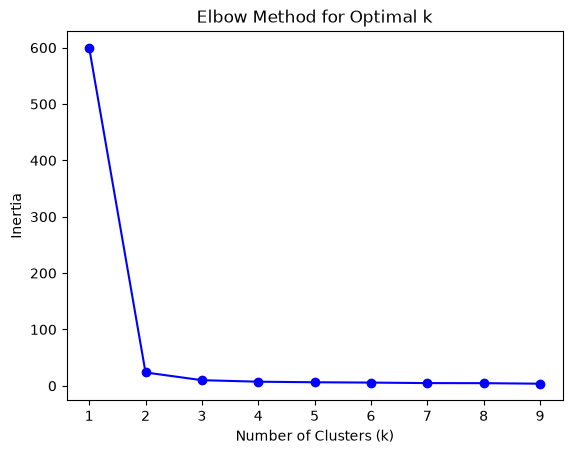

[600.0, 23.7, 10.0, 7.3, 6.3, 5.7, 4.8, 4.7, 3.8]


In [11]:
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024)
    km.fit(X)
    inertia.append(km.inertia_)
plt.plot(k_values, inertia, 'bo-')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()
print([round(v, 1) for v in inertia])

**Verification against the book:** Figure 10.3 is reproduced (inertia 600 → 23.7 → 10.0 → 7.3 → …) ✔ and "two to three clusters are the optimal choices for k".

> **Book correction / caution (the elbow says 2, the truth is 4).** The elbow is sharp at *k* = 2 because the four blobs are **two touching pairs** (Figure 10.1); the drop from 2 to 4 clusters (23.7 → 7.3) is invisible next to the 600 → 24 drop on a linear axis. The data were generated with four centres, and four clusters is what the ground truth says (ARI 0.80–0.81 at *k* = 4). The elbow is a heuristic that answers "how many *well-separated groups* are there", not "how many generating centres".
> The next cell compares the elbow with the silhouette score and the Davies-Bouldin index (both need no labels) and with the ARI (needs labels):

,inertia,silhouette (higher=better),Davies-Bouldin (lower=better),Calinski-Harabasz (higher=better),ARI vs truth
k,,,,,
2,23.679,0.880,0.181,7252.857,0.497
3,9.993,0.784,0.356,8768.078,0.697
4,7.295,0.531,0.727,8019.623,0.801
5,6.305,0.451,0.845,6947.361,0.709
6,5.724,0.400,0.957,6109.957,0.630
7,4.827,0.420,0.882,6021.067,0.601
8,4.685,0.418,0.861,5301.687,0.597


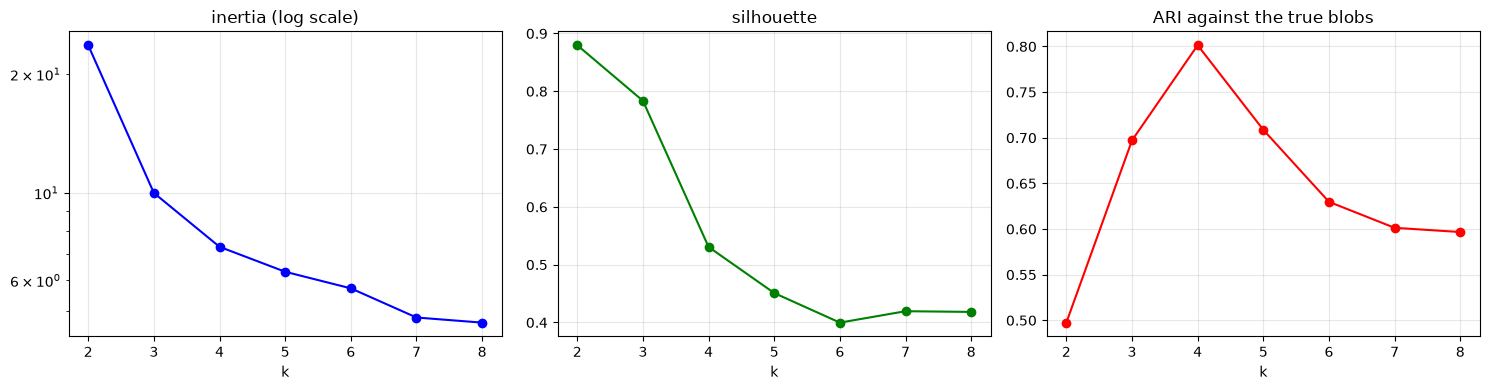

In [12]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=2024).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette (higher=better)": silhouette_score(X, km.labels_),
                 "Davies-Bouldin (lower=better)": davies_bouldin_score(X, km.labels_),
                 "Calinski-Harabasz (higher=better)": calinski_harabasz_score(X, km.labels_),
                 "ARI vs truth": adjusted_rand_score(y_true, km.labels_)})
tab = pd.DataFrame(rows).set_index("k")
display(tab.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogy(tab.index, tab["inertia"], "bo-"); ax[0].set_title("inertia (log scale)")
ax[1].plot(tab.index, tab["silhouette (higher=better)"], "go-"); ax[1].set_title("silhouette")
ax[2].plot(tab.index, tab["ARI vs truth"], "ro-"); ax[2].set_title("ARI against the true blobs")
for a in ax: a.set_xlabel("k"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The criteria **disagree**. Silhouette (0.880) and Davies-Bouldin (0.181) are best at *k* = 2, Calinski-Harabasz at *k* = 3 (8,768), and only the ARI against the truth peaks at *k* = 4 (0.801). On this data the internal metrics answer "how many well-separated groups are there?" (two touching pairs), while "four generating centres" can only be recovered with labels or knowledge of how the data were made. A careful analyst could defend 2, 3 or 4 clusters here — which is exactly what the book means by "more of an art than a science".

### Theory — K-means
* **Objective:** minimise $\sum_k\sum_{x\in C_k}\lVert x-\mu_k\rVert^2$ (inertia). Each assign/update step can only lower it, so the algorithm converges — to a **local** minimum (hence `n_init`).
* **Cost:** $O(n\,k\,d)$ per iteration — scales to millions of points (`MiniBatchKMeans` for even more).
* **Assumptions:** Euclidean distance, similar-sized, roughly spherical clusters, *k* known; every point is assigned to a cluster (no noise).
* **Choosing *k*:** elbow (subjective), silhouette / Davies-Bouldin (geometric, biased towards few compact groups), domain knowledge, stability across seeds. They can disagree — and none is a substitute for looking at the data.

### Hands-on workflow (book)
Generate or load unlabelled data, fit `KMeans`, plot clusters and centroids, apply the elbow method, and try other initialisations and values of *k*.

## 3. Hierarchical clustering

**Summary.** Hierarchical clustering builds **nested clusters** by merging (agglomerative, bottom-up) or splitting (divisive, top-down) successively. It needs no *k* in advance and produces a tree, the **dendrogram**. scikit-learn implements the agglomerative approach, which this recipe uses.

### Getting ready

In [13]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

### How to do it…
Either give the number of clusters, or a distance threshold at which to cut the tree.

In [14]:
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

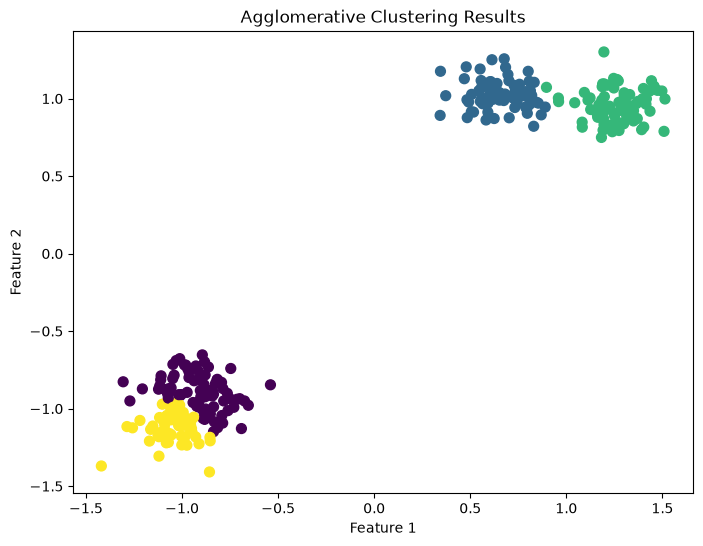

cluster sizes: [82 74 76 68] | ARI vs truth: 0.793


In [15]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
print("cluster sizes:", np.bincount(y_agg), "| ARI vs truth:", round(adjusted_rand_score(y_true, y_agg), 3))

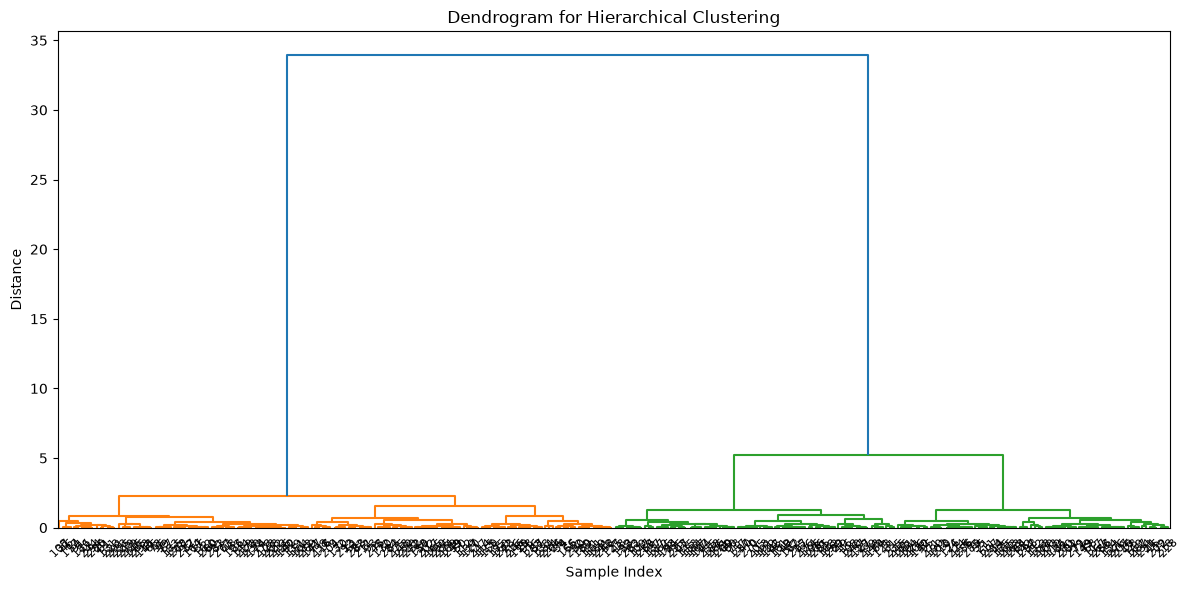

In [16]:
linked = linkage(X, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Verification against the book:** Figures 10.4 and 10.5 — four clusters and the Ward dendrogram ✔ (sizes 82 / 74 / 76 / 68, ARI 0.79: slightly worse than K-means' 0.80 on this data). As the book's note says, the 300 leaf labels are unreadable; what matters is the *heights*: the tall vertical lines near the top are the expensive merges.

### How it works…
Agglomerative clustering starts with every point as its own cluster and repeatedly merges the **two closest** clusters, until one remains or a stopping condition (a number of clusters or a distance) is met. "Closest" is defined by the **linkage**: *Ward* (minimise the increase in within-cluster variance — the default), *complete* (maximum pairwise distance), *average*, *single* (minimum distance).
**Extension — linkage matters, and the dendrogram tells you *k*.** The same 4 clusters with each linkage, the heights of the last merges recorded in the linkage matrix, and the equivalence between scikit-learn's labels and cutting the SciPy tree:

In [17]:
from scipy.cluster.hierarchy import fcluster

rows = {}
for l in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=4, linkage=l).fit_predict(X)
    rows[l] = {"ARI vs truth": adjusted_rand_score(y_true, lab), "cluster sizes": np.bincount(lab).tolist()}
display(pd.DataFrame(rows).T)

print("heights of the last 5 merges (Ward):", linked[-5:, 2].round(2), "  <- the merges that leave 5, 4, 3, 2, 1 clusters")
cut = fcluster(linked, t=4, criterion="maxclust")
print("scipy tree cut into 4 clusters == sklearn labels (ARI between them):", adjusted_rand_score(y_agg, cut))
ag_thr = AgglomerativeClustering(n_clusters=None, distance_threshold=5).fit(X)
print("distance_threshold=5 (no n_clusters) ->", ag_thr.n_clusters_, "clusters")

,ARI vs truth,cluster sizes
ward,0.7926,"[82, 74, 76, 68]"
complete,0.746527,"[87, 76, 74, 63]"
average,0.695992,"[149, 77, 73, 1]"
single,0.494224,"[150, 148, 1, 1]"


heights of the last 5 merges (Ward): [ 1.28  1.58  2.25  5.21 33.95]   <- the merges that leave 5, 4, 3, 2, 1 clusters
scipy tree cut into 4 clusters == sklearn labels (ARI between them): 1.0
distance_threshold=5 (no n_clusters) -> 3 clusters


Ward gives the best partition (ARI 0.79); complete linkage is a little worse (0.75), and average (0.70) and single (0.49) break down by **chaining**: single linkage returns clusters of 150, 148, 1 and 1 points — two stray points become "clusters" — and average linkage likewise produces a one-point cluster.
The merge heights show the same two-pairs structure as the elbow: the last merges leave 5, 4, 3, 2, 1 clusters at heights 1.28, 1.58, 2.25, 5.21 and 33.95 — a huge gap before the final merge (two well-separated groups), a smaller one before 3 → 2, and almost none between 5 and 4 clusters. A cut at height 5 (just below 5.21) therefore gives 3 clusters, exactly what `distance_threshold=5` returned. Cutting the SciPy tree into 4 clusters reproduces scikit-learn's labels exactly (ARI 1.0).

A readable dendrogram: show only the last 12 merges (`truncate_mode="lastp"`), with the cut at height 5 drawn in:

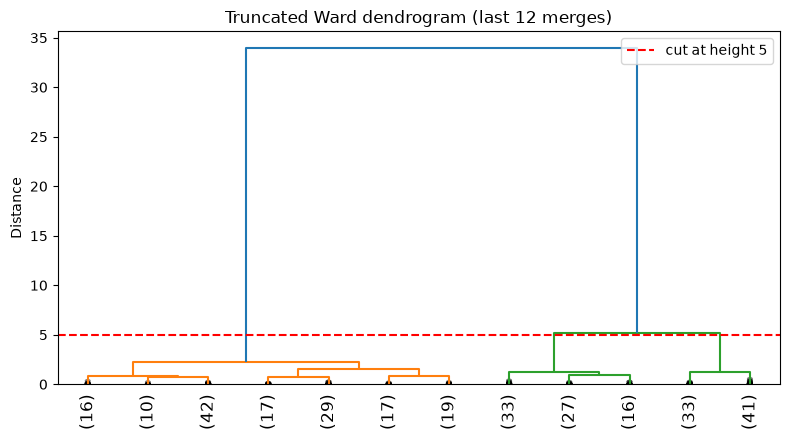

In [18]:
plt.figure(figsize=(8, 4.5))
dendrogram(linked, truncate_mode="lastp", p=12, leaf_rotation=90, show_contracted=True)
plt.axhline(5, color="red", ls="--", label="cut at height 5")
plt.title("Truncated Ward dendrogram (last 12 merges)"); plt.ylabel("Distance"); plt.legend(); plt.tight_layout(); plt.show()

### There's more…
Dendrograms show whether natural groupings exist: **gaps** in the merge heights suggest where to cut. scikit-learn has no divisive (top-down) clustering, although bisecting K-means (`sklearn.cluster.BisectingKMeans`, added in 1.1) is a related top-down method.

### Theory — hierarchical clustering
* **Cost:** the pairwise distance matrix needs $O(n^2)$ memory and time $O(n^2\log n)$ or worse — fine for thousands of points, not for millions (timings in Section 6).
* **Deterministic:** no random initialisation; the dendrogram is fixed by the data and the linkage.
* **Linkage = inductive bias:** Ward → compact, similar-sized clusters (like K-means); single → long chains (it can follow elongated shapes but is sensitive to noise); complete/average in between.
* A cut at a height (`distance_threshold`) or at *k* clusters (`n_clusters`) gives the flat clustering.

### Hands-on workflow (book)
Reuse or generate a dataset, apply `AgglomerativeClustering()` with different linkages, plot the clusters, draw the dendrogram with `scipy.cluster.hierarchy` and cut it at different levels to see how the number of clusters changes.

## 4. Density-based clustering with DBSCAN

**Summary.** DBSCAN (Density-Based Spatial Clustering of Applications with Noise) finds clusters of **varying shapes and sizes**, needs no number of clusters, and labels isolated points as **noise**. It does not generate centroids.

### Getting ready — two crescents
`make_moons` creates two interleaved half-circles, a shape K-means cannot recover.

In [19]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

In [20]:
X, _ = make_moons(n_samples=300, noise=0.1,
                  random_state=2024)

(The book discards the labels again; here they are kept as `y_moons` for scoring.)

### How to do it…
The two most important arguments are `eps` (neighbourhood radius) and `min_samples`: here 0.2 and 5.

In [21]:
X_m, y_moons = make_moons(n_samples=300, noise=0.1, random_state=2024)      # same data, labels kept for scoring only
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X)
print("labels found:", dict(zip(*np.unique(y_db, return_counts=True))), "(-1 = noise) | ARI vs the 2 moons:", round(adjusted_rand_score(y_moons, y_db), 3))

labels found: {np.int64(-1): np.int64(4), np.int64(0): np.int64(150), np.int64(1): np.int64(146)} (-1 = noise) | ARI vs the 2 moons: 0.96


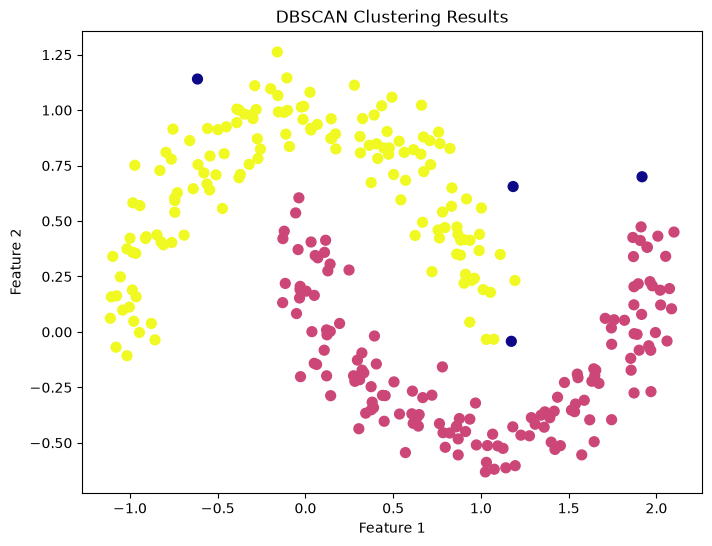

In [22]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_db, cmap='plasma', s=50)
plt.title("DBSCAN Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Verification against the book:** Figure 10.6 — the two crescents are separated and **4 points** (dark) are flagged as noise (`-1`) ✔ (150 + 146 points in the two clusters; ARI 0.96 against the true moons).

### How it works…
Two parameters define density: `eps` (radius of the neighbourhood) and `min_samples` (points needed in it to count as dense). Every point is then one of:
* **core** — at least `min_samples` points within `eps` (the point itself counts);
* **border** — within `eps` of a core point but with fewer than `min_samples` neighbours itself;
* **noise** — neither.

Clusters grow by repeatedly adding the density-connected neighbours of core points. Counting the three types on this data:

In [23]:
core = np.zeros(len(X), dtype=bool)
core[dbscan.core_sample_indices_] = True
noise = dbscan.labels_ == -1
print(f"core points: {core.sum()} | border points: {(~core & ~noise).sum()} | noise points: {noise.sum()}")

km_m = KMeans(n_clusters=2, random_state=2024).fit_predict(X)
print("K-means (k=2) on the same data: ARI =", round(adjusted_rand_score(y_moons, km_m), 3), "  vs DBSCAN:", round(adjusted_rand_score(y_moons, y_db), 3))

core points: 290 | border points: 6 | noise points: 4
K-means (k=2) on the same data: ARI = 0.241   vs DBSCAN: 0.96


K-means cuts each crescent in half: it can only draw straight boundaries between centroids, so convex Voronoi cells cannot follow a curved shape.

### There's more… — choosing `eps` and `min_samples`
The book's heuristic: plot the sorted distance of every point to its *k*-th nearest neighbour (k = `min_samples`) and look for the elbow.

In [24]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, 4])

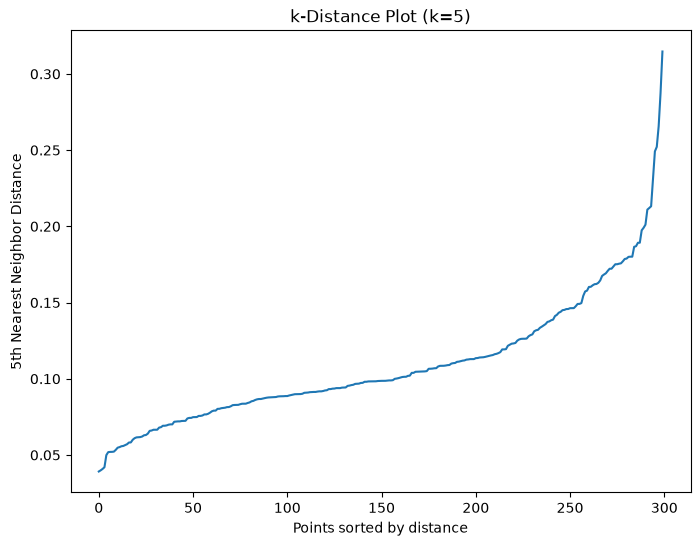

column 0 is the distance of each point to itself (all zero): True
so column 4 is the 4th *other* neighbour; DBSCAN's min_samples=5 also counts the point itself -> consistent
quantiles of the plotted distance (50/90/95/99/100%): [0.099 0.169 0.187 0.252 0.315]


In [25]:
plt.figure(figsize=(8, 6))
plt.plot(distances)
plt.title("k-Distance Plot (k=5)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()

d_all, _ = neighbors_fit.kneighbors(X)
print("column 0 is the distance of each point to itself (all zero):", np.allclose(d_all[:, 0], 0))
print("so column 4 is the 4th *other* neighbour; DBSCAN's min_samples=5 also counts the point itself -> consistent")
print("quantiles of the plotted distance (50/90/95/99/100%):", np.quantile(distances, [.5, .9, .95, .99, 1]).round(3))

**Verification against the book:** Figure 10.7 — a flat curve around 0.1 that bends upwards at ≈ 0.17–0.2 and shoots up for the last few points ✔: the elbow supports the book's `eps=0.2`. (Minor: the y label says "5th nearest neighbour", but column 0 is the point itself, so the plotted value is the distance to the **4th other** point — exactly what a core-point test with `min_samples=5` needs, since DBSCAN counts the point itself.)

**Extension — how sensitive is DBSCAN?** ARI against the true moons, number of clusters and noise points over a grid of `eps` and `min_samples`:

In [26]:
rows = []
for eps in [0.1, 0.15, 0.2, 0.25, 0.3]:
    for ms in [3, 5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit(X).labels_
        rows.append({"eps": eps, "min_samples": ms, "clusters": len(set(lab)) - (1 if -1 in lab else 0),
                     "noise points": int((lab == -1).sum()), "ARI": adjusted_rand_score(y_moons, lab)})
grid = pd.DataFrame(rows)
display(grid.pivot(index="eps", columns="min_samples", values="ARI").round(3).style.background_gradient(cmap="Blues", vmin=0, vmax=1).format("{:.3f}").set_caption("ARI"))
print("number of clusters found:"); display(grid.pivot(index="eps", columns="min_samples", values="clusters"))
print("number of noise points:"); display(grid.pivot(index="eps", columns="min_samples", values="noise points"))

min_samples,3,5,10
eps,,,
0.100000,0.117,0.088,0.008
0.150000,0.626,0.618,0.214
0.200000,0.967,0.960,0.935
0.250000,0.000,0.000,0.980
0.300000,0.000,0.000,0.000


number of clusters found:


min_samples,3,5,10
eps,,,
0.10,16,18,1
0.15,5,4,8
0.20,2,2,2
0.25,1,1,2
0.30,1,1,1


number of noise points:


min_samples,3,5,10
eps,,,
0.10,34,62,286
0.15,5,12,77
0.20,3,4,8
0.25,0,0,1
0.30,0,0,0


DBSCAN is **sensitive**: the right answer (2 clusters, ARI 0.94–0.97) exists in a narrow window around the book's `eps=0.2` (for all three `min_samples`). Below it, the moons shatter — at `eps=0.1` there are 16–18 clusters, and with `min_samples=10` almost everything (286 of 300 points) is noise. Above it (`eps` ≥ 0.25 with `min_samples` ≤ 5, and every `eps=0.3` run) the two crescents are merged into **one** cluster (ARI 0). Only `eps=0.25, min_samples=10` still finds two clusters (ARI 0.98) — larger `min_samples` demands more density to connect and so keeps the crescents apart. The k-distance elbow (≈ 0.17–0.2) points to the working window, and nothing but plots or labels tells you you have missed it.

### Theory — DBSCAN
* **Strengths:** arbitrary cluster shapes, automatic number of clusters, explicit noise, one pass over neighbourhood queries (≈ $O(n\log n)$ with a spatial index).
* **Weaknesses:** one global density (`eps`) — it cannot handle clusters of very different densities (HDBSCAN, available as `sklearn.cluster.HDBSCAN` since 1.3, relaxes this); sensitivity to `eps` (as the grid shows) and to feature scaling; no `predict` for new points; distances lose meaning in high dimensions.
* **Rules of thumb:** `min_samples` ≥ dimensions + 1 (often 2 × dimensions); read `eps` from the k-distance elbow; standardise first.

### Hands-on workflow (book)
Create a noisy dataset (`make_moons`, `make_circles`), apply `DBSCAN`, visualise which points are noise, draw the k-distance plot to choose `eps` and try different `eps` / `min_samples` combinations — as above.

## 5. Cluster evaluation metrics

**Summary.** Without labels, evaluating a clustering is hard. The book uses two **internal** metrics, which look only at the data and the clusters — the **silhouette score** and the **Davies-Bouldin index** — and one **external** metric that compares with known true labels, the **Adjusted Rand Index (ARI)**.

### Getting ready
A labelled blob dataset (this time **not** scaled, unlike the previous K-means recipe) and a 4-cluster K-means.

In [27]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

In [28]:
X, y_true = make_blobs(
    n_samples=300, centers=4,
    cluster_std=0.60, random_state=2024
)

In [29]:
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

### How to do it…

In [30]:
sil_score = silhouette_score(X, y_kmeans)
print(f"Silhouette Score: {sil_score:.3f}")

Silhouette Score: 0.534


In [31]:
db_index = davies_bouldin_score(X, y_kmeans)
print(f"Davies-Bouldin Index: {db_index:.3f}")

Davies-Bouldin Index: 0.702


In [32]:
ari = adjusted_rand_score(y_true, y_kmeans)
print(f"Adjusted Rand Index: {ari:.3f}")

Adjusted Rand Index: 0.814


**Verification against the book:** the book's output — Silhouette **0.534**, Davies-Bouldin **0.702**, Adjusted Rand Index **0.814** — is reproduced exactly ✔. (They belong to the *unscaled* data: on the scaled data of the K-means recipe the same model gives 0.531 / 0.727 / 0.801, so a different preprocessing changes all three numbers.)

### How it works…
* **Silhouette score:** for each point, $s=\frac{b-a}{\max(a,b)}$ with *a* = mean distance to its own cluster, *b* = mean distance to the nearest other cluster. It runs from −1 to 1; values near 1 mean dense, well-separated clusters, near 0 overlapping clusters, **negative values mean the point is probably in the wrong cluster**.
* **Davies-Bouldin index:** the average, over clusters, of the similarity ratio (within-cluster scatter ÷ distance between centroids) with the most similar other cluster. **Lower is better** (0 is the minimum); it penalises clusters that are wide and close together.
* **Adjusted Rand Index:** compares two clusterings by counting pairs of points that are in the same / different clusters in both, **corrected for chance**: 1 = identical partitions, ≈ 0 = random, it can be slightly negative.

**Extension — check them by hand and test their properties.** The silhouette of one point computed from the definition; ARI is invariant to how the clusters are *named*, and random labels score ≈ 0:

In [33]:
from sklearn.metrics import silhouette_samples, normalized_mutual_info_score
from scipy.spatial.distance import cdist

i = 0
own = y_kmeans[i]
a = cdist(X[[i]], X[(y_kmeans == own) & (np.arange(len(X)) != i)]).mean()
b = min(cdist(X[[i]], X[y_kmeans == k]).mean() for k in range(4) if k != own)
print(f"silhouette of point 0 by hand: {(b - a) / max(a, b):.4f} | silhouette_samples: {silhouette_samples(X, y_kmeans)[i]:.4f}")
print(f"mean of all per-point silhouettes = silhouette_score: {silhouette_samples(X, y_kmeans).mean():.4f}; points with s < 0: {(silhouette_samples(X, y_kmeans) < 0).sum()}")

renamed = (y_kmeans + 1) % 4                     # same partition, different cluster names
rng = np.random.RandomState(0)
print("\nARI after renaming the clusters:", round(adjusted_rand_score(y_true, renamed), 3), "(unchanged)")
print("ARI of random labels:", round(np.mean([adjusted_rand_score(y_true, rng.randint(0, 4, len(X))) for _ in range(50)]), 3), "(≈ 0, thanks to the chance correction)")
print("normalized mutual information (another external metric):", round(normalized_mutual_info_score(y_true, y_kmeans), 3))

silhouette of point 0 by hand: 0.6090 | silhouette_samples: 0.6090
mean of all per-point silhouettes = silhouette_score: 0.5343; points with s < 0: 2

ARI after renaming the clusters: 0.814 (unchanged)


ARI of random labels: -0.0 (≈ 0, thanks to the chance correction)
normalized mutual information (another external metric): 0.828


**Extension — internal metrics are not a substitute for the truth.** Silhouette and Davies-Bouldin favour compact, convex clusters. Compare K-means and DBSCAN on the two moons from the previous section: the *wrong* partition (K-means) looks better to the silhouette than the *correct* one (DBSCAN):

In [34]:
labels_db = DBSCAN(eps=0.2, min_samples=5).fit_predict(X_m)
labels_km = KMeans(n_clusters=2, random_state=2024).fit_predict(X_m)
core_pts = labels_db != -1
rows = {"K-means (k=2)": {"silhouette": silhouette_score(X_m, labels_km), "Davies-Bouldin": davies_bouldin_score(X_m, labels_km), "ARI vs truth": adjusted_rand_score(y_moons, labels_km)},
        "DBSCAN (noise excluded)": {"silhouette": silhouette_score(X_m[core_pts], labels_db[core_pts]), "Davies-Bouldin": davies_bouldin_score(X_m[core_pts], labels_db[core_pts]), "ARI vs truth": adjusted_rand_score(y_moons, labels_db)}}
display(pd.DataFrame(rows).T.round(3))

,silhouette,Davies-Bouldin,ARI vs truth
K-means (k=2),0.477,0.788,0.241
DBSCAN (noise excluded),0.331,1.144,0.960


Both internal metrics prefer K-means' **wrong**, straight-line cut — silhouette 0.477 vs 0.331 and Davies-Bouldin 0.788 vs 1.144 (lower is better) — over DBSCAN's correct crescents, whose ARI is 0.96 against 0.24. Internal metrics reward compact, convex clusters, so they cannot recognise a good non-convex clustering (and DBSCAN's score was computed without its 4 noise points, which if anything flatters it). Use them to compare solutions of the *same kind* (different *k* for K-means), not to choose between algorithms with different inductive biases.

### There's more…
The **Calinski-Harabasz index** (variance-ratio criterion; higher is better) is another internal score based on between- vs within-cluster dispersion; it is in the table of Section 2.

### Theory — evaluating clusterings
* **Internal metrics** (silhouette, Davies-Bouldin, Calinski-Harabasz) need no labels but measure *geometry* (compactness and separation) — they favour convex clusters and are not comparable across different feature representations.
* **External metrics** (ARI, NMI) compare with a reference labelling; use them for benchmarks or when a small labelled sample exists. ARI is chance-corrected, so unlike the plain Rand index it is ≈ 0 for random labels.
* **Use several, together with plots and domain judgement.** The same model scored 0.534 / 0.702 / 0.814 here and 0.531 / 0.727 / 0.801 after scaling.

### Hands-on workflow (book)
Generate or load a dataset, fit `KMeans` (or another algorithm), compute the silhouette and Davies-Bouldin scores, add ARI when ground truth is available, and vary the number of clusters to see how the metrics respond (Section 2 does this).

## 6. Choosing the right clustering algorithm

**Summary.** There is no one-size-fits-all algorithm: the best choice depends on cluster shape, noise, size of the data and dimensionality. The recipe builds three datasets with different geometry.

### Getting ready

In [35]:
from sklearn.datasets import (
    make_moons, make_blobs, make_circles)
from sklearn.preprocessing import StandardScaler

> **Book correction (a typesetting slip).** The printed import contains `make_ circles` (with a space), which would be a `SyntaxError` if copied; it is `make_circles`.

In [36]:
X_blobs, _ = make_blobs(
    n_samples=300, centers=3,
    cluster_std=0.6, random_state=2024
)
X_moons, _ = make_moons(
    n_samples=300, noise=0.1,
    random_state=2024
)
X_circles, _ = make_circles(
    n_samples=300, noise=0.05,
    factor=0.5, random_state=2024
)
X_blobs = StandardScaler().fit_transform(X_blobs)
X_moons = StandardScaler().fit_transform(X_moons)
X_circles = StandardScaler().fit_transform(X_circles)

### How to do it…

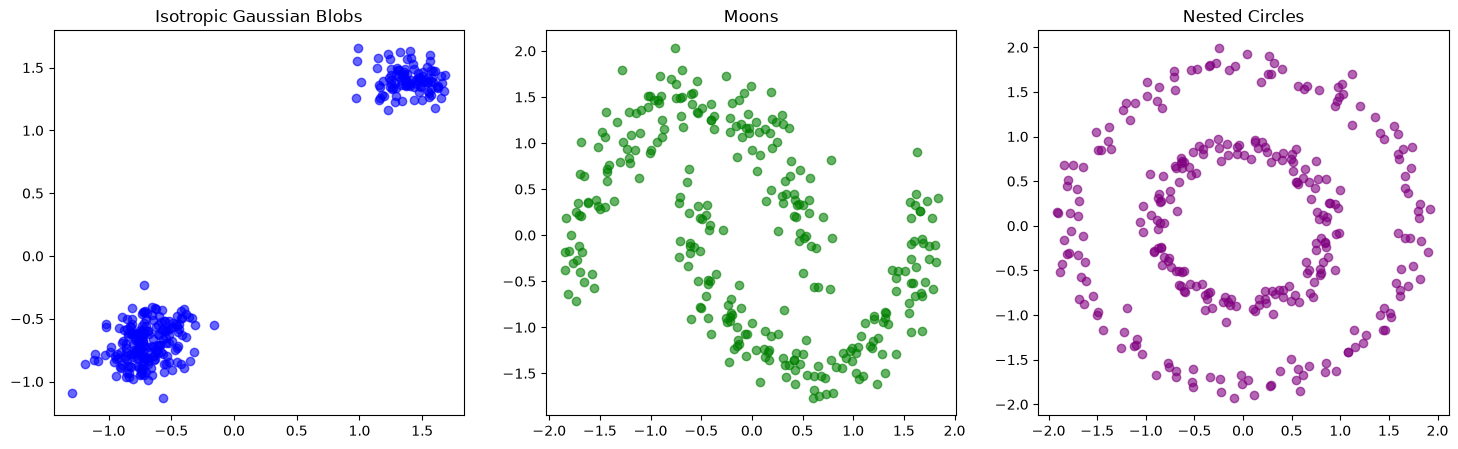

In [37]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].scatter(X_blobs[:, 0], X_blobs[:, 1],
               c='blue', alpha=0.6)
axs[0].set_title("Isotropic Gaussian Blobs")
axs[1].scatter(X_moons[:, 0], X_moons[:, 1],
               c='green', alpha=0.6)
axs[1].set_title("Moons")
axs[2].scatter(X_circles[:, 0], X_circles[:, 1],
               c='purple', alpha=0.6)
axs[2].set_title("Nested Circles")
plt.show()

**Verification against the book:** Figure 10.8 — blobs, moons and nested circles ✔. The book describes them as "ideal for K-means or hierarchical clustering", "better suited for DBSCAN" and "challenging for many algorithms but handled well by DBSCAN" — but never *runs* the algorithms. Here is the missing experiment: K-means, Ward agglomerative clustering and DBSCAN on each dataset (the true labels are used only for the ARI in each title):

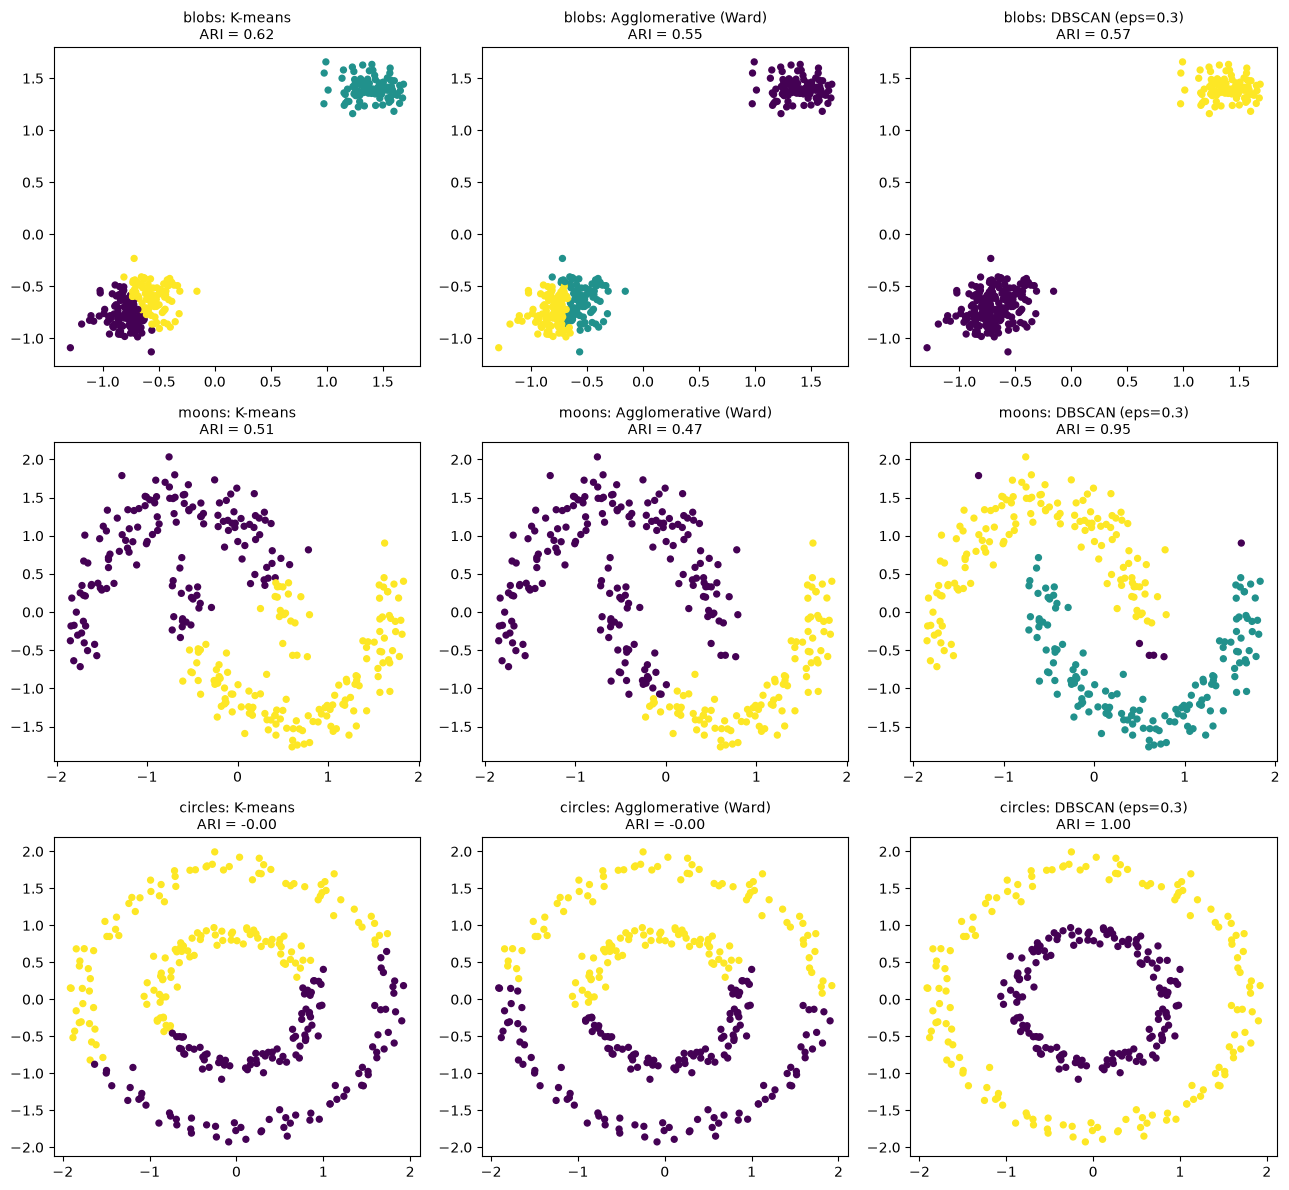

,K-means,Agglomerative (Ward),DBSCAN (eps=0.3)
blobs,0.623,0.552,0.570
moons,0.507,0.470,0.948
circles,-0.003,-0.003,1.000


In [38]:
y_blobs = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)[1]
y_moons2 = make_moons(n_samples=300, noise=0.1, random_state=2024)[1]
y_circles = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)[1]

datasets = {"blobs": (X_blobs, y_blobs, 3), "moons": (X_moons, y_moons2, 2), "circles": (X_circles, y_circles, 2)}
fig, axs = plt.subplots(3, 3, figsize=(13, 12))
ari_table = {}
for r, (name, (Xd, yd, k)) in enumerate(datasets.items()):
    algos = {"K-means": KMeans(n_clusters=k, random_state=2024, n_init=10),
             "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=k),
             "DBSCAN (eps=0.3)": DBSCAN(eps=0.3, min_samples=5)}
    for c, (aname, algo) in enumerate(algos.items()):
        lab = algo.fit_predict(Xd)
        ari = adjusted_rand_score(yd, lab)
        ari_table.setdefault(name, {})[aname] = ari
        axs[r, c].scatter(Xd[:, 0], Xd[:, 1], c=lab, cmap="viridis", s=18)
        axs[r, c].set_title(f"{name}: {aname}\nARI = {ari:.2f}", fontsize=10)
plt.tight_layout(); plt.show()
display(pd.DataFrame(ari_table).T.round(3))

Reading the grid: DBSCAN is the only method that recovers the moons (ARI 0.95) and the circles (1.00); K-means and Ward fail on both (circles: −0.00 — they cut the rings into halves). On the three-blob data **none** of the three methods gets above 0.62 — not because they are bad, but because with this seed two of the three blobs overlap (lower-left clump): K-means and Ward split that clump arbitrarily, while DBSCAN with `eps=0.3` fuses the two touching blobs into one cluster. So the book's "isotropic blobs (ideal for K-means or hierarchical clustering)" holds only when the blobs are separated, and DBSCAN is not "worse" here — it answers a different question (density-connected regions).

### How it works…
The book's decision factors:
* **Cluster shape** — K-means suits convex clusters; DBSCAN/spectral clustering suit non-convex ones.
* **Noise** — DBSCAN labels outliers explicitly; K-means and hierarchical clustering assign every point to a cluster.
* **Scalability** — K-means scales well; hierarchical clustering does not (time/memory).
* **Parameter sensitivity** — *k* and initialisation (K-means), `eps` and `min_samples` (DBSCAN), linkage and stopping criterion (agglomerative).
* **Dimensionality** — high dimensions usually need dimensionality reduction first (the curse of dimensionality).

Two of these claims are easy to measure. **Scalability:** wall-clock time to cluster 4 blobs of increasing size:

In [39]:
import time
from sklearn.cluster import SpectralClustering

rows = {}
for n in [1000, 2000, 4000, 8000]:
    Xn, _ = make_blobs(n_samples=n, centers=4, cluster_std=0.6, random_state=0)
    rows[n] = {}
    for name, m in [("K-means", KMeans(4, n_init=1, random_state=0)), ("Agglomerative (Ward)", AgglomerativeClustering(4)),
                    ("DBSCAN", DBSCAN(eps=0.3, min_samples=5)),
                    ("Spectral (kNN graph)", SpectralClustering(4, affinity="nearest_neighbors", random_state=0)),
                    ("Spectral (rbf, dense n x n)", SpectralClustering(4, affinity="rbf", random_state=0))]:
        if n > 4000 and name.startswith("Spectral"):
            rows[n][name] = np.nan; continue
        t0 = time.perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(Xn)
        rows[n][name] = time.perf_counter() - t0
display(pd.DataFrame(rows).round(2).rename_axis(columns="n samples"))

n samples,1000,2000,4000,8000
K-means,0.02,0.01,0.01,0.01
Agglomerative (Ward),0.03,0.11,0.47,1.97
DBSCAN,0.01,0.02,0.04,0.11
Spectral (kNN graph),0.18,0.11,0.11,NaN
"Spectral (rbf, dense n x n)",0.53,0.53,1.77,NaN


K-means stays at ≈ 0.01–0.02 s for every size and DBSCAN (with a spatial index) needs about 0.1 s at 8,000 points. Agglomerative clustering grows roughly quadratically — from 0.03 s at 1,000 points to about 2 s at 8,000 (≈ 60× for 8× the data) — and its distance matrix needs O(n²) memory, confirming the book's "less scalable". Spectral clustering with the sparse nearest-neighbour graph was cheap at these sizes (0.1–0.2 s), but the RBF version, which builds a dense n × n affinity matrix, took 0.5–1.8 s (≈ 50–180× K-means) and was skipped beyond 4,000 points. (One run on one machine: read orders of magnitude, not exact values.)

**Dimensionality:** distances concentrate as the dimension grows — the nearest and the farthest neighbour become almost equally far — which undermines every distance- or density-based method:

In [40]:
from scipy.spatial.distance import pdist

rng = np.random.RandomState(0)
rows = {}
for d in [2, 10, 100, 1000]:
    D = pdist(rng.uniform(size=(300, d)))
    rows[d] = {"min distance": D.min(), "max distance": D.max(), "(max - min) / min": (D.max() - D.min()) / D.min(), "std / mean": D.std() / D.mean()}
display(pd.DataFrame(rows).T.rename_axis(index="dimensions").round(3))

,min distance,max distance,(max - min) / min,std / mean
dimensions,,,,
2,0.002,1.324,765.014,0.473
10,0.320,2.209,5.911,0.193
100,3.063,5.198,0.697,0.058
1000,11.904,13.929,0.170,0.019


The relative contrast (max − min)/min of the pairwise distances collapses from 765 in 2 dimensions to 5.9 (10 d), 0.70 (100 d) and 0.17 (1,000 d), and std/mean of the distances falls from 0.47 to 0.02: in 1,000 dimensions the farthest point is only 17% farther than the nearest one, so "nearest" and "dense" lose their meaning — which is why the book recommends reducing the dimension first. (Uniform random data, 300 points.)

### There's more…
The book's Table 10.1 recommends: convex clusters → K-means; non-convex → DBSCAN or spectral; noise/outliers → DBSCAN; small datasets → hierarchical; large datasets → K-means or `MiniBatchKMeans`. The experiments above support it, with the caveats noted. Always plot the raw data first, and consider combining clustering with dimensionality reduction (PCA, t-SNE) for high-dimensional data (Exercise 3).

### Theory — a practical recipe
1. Plot the data (or a 2-D projection): look for shape, density differences and outliers.
2. Standardise features that have different units.
3. Start with K-means (and K-means++ with several restarts) as a baseline; if clusters are not convex or contain noise, try DBSCAN; if you need a hierarchy or have few points, try agglomerative clustering.
4. Evaluate with several metrics *and* a look at the clusters; check stability across seeds and subsamples.

### Hands-on workflow (book)
Create datasets with different spatial characteristics, visualise them, apply K-means, DBSCAN and agglomerative clustering to each, compare with plots and metrics, and for high-dimensional data apply PCA before clustering — done above and in Exercise 3.

## 7. Advanced clustering techniques

**Summary.** Two further scikit-learn methods give more flexibility: **spectral clustering** (graph-based, handles complex shapes) and **Gaussian Mixture Models** (GMMs: probabilistic, soft assignments).

### Getting ready

In [41]:
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture

In [42]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
X, _ = make_moons(n_samples=300, noise=0.05,
                  random_state=2024)
X = StandardScaler().fit_transform(X)
y_moons05 = make_moons(n_samples=300, noise=0.05, random_state=2024)[1]       # labels, for scoring only

### How to do it…

In [43]:
with warnings.catch_warnings(record=True) as caught:        # see (rather than print) the library warning
    warnings.simplefilter("always")
    spectral = SpectralClustering(
        n_clusters=2,
        affinity='nearest_neighbors',
        random_state=2024
    )
    y_spectral = spectral.fit_predict(X)
print("warnings raised by SpectralClustering:", sorted({str(w.message) for w in caught}))

from scipy.sparse.csgraph import connected_components
n_comp, comp = connected_components(spectral.affinity_matrix_, directed=False)
print("connected components of the affinity graph built with n_neighbors=10:", n_comp, "| sizes:", np.bincount(comp).tolist())
with warnings.catch_warnings(record=True) as caught15:
    warnings.simplefilter("always")
    lab15 = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', n_neighbors=15, random_state=2024).fit_predict(X)
print("with n_neighbors=15 -> warnings:", len(caught15), "| ARI:", round(adjusted_rand_score(y_moons05, lab15), 3))

warnings raised by SpectralClustering: ['Graph is not fully connected, spectral embedding may not work as expected.']
connected components of the affinity graph built with n_neighbors=10: 2 | sizes: [150, 150]
with n_neighbors=15 -> warnings: 0 | ARI: 1.0


In [44]:
gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X)

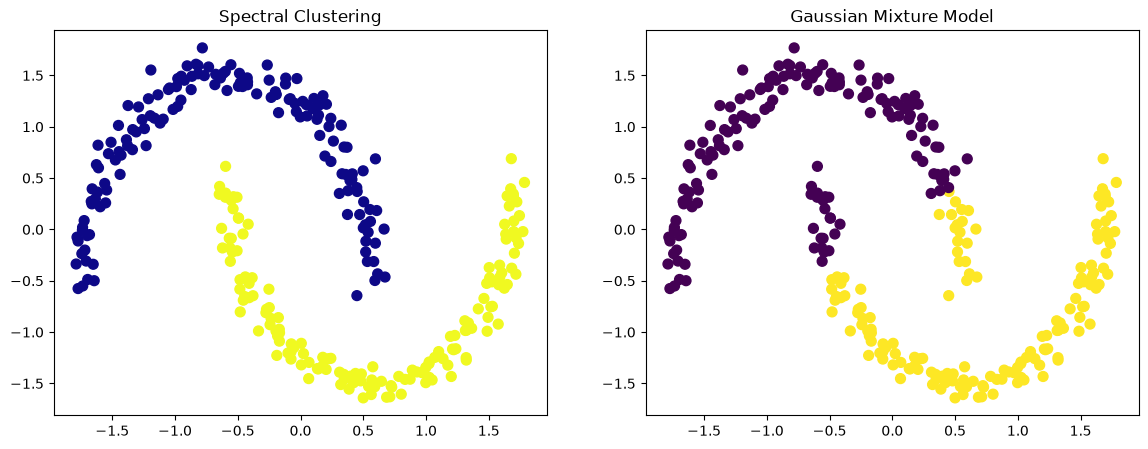

ARI vs the 2 moons -> spectral: 1.0 | GMM: 0.526


In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(
    X[:, 0], X[:, 1], c=y_spectral,
    cmap='plasma', s=50
)
ax1.set_title("Spectral Clustering")
ax2.scatter(
    X[:, 0], X[:, 1], c=y_gmm,
    cmap='viridis', s=50
)
ax2.set_title("Gaussian Mixture Model")
plt.show()
print("ARI vs the 2 moons -> spectral:", round(adjusted_rand_score(y_moons05, y_spectral), 3), "| GMM:", round(adjusted_rand_score(y_moons05, y_gmm), 3))

**Verification against the book:** Figure 10.9 — spectral clustering separates the two crescents (ARI **1.0**), while the GMM cuts them with an oblique line (ARI 0.53) ✔; "spectral clustering handles the curved shape better".
The `UserWarning: Graph is not fully connected` is real and informative: the affinity graph built with the default `n_neighbors=10` splits into the connected components printed above (one per crescent, no edge links the two). Here that is harmless — separating disconnected groups is exactly what spectral clustering does, and the result is perfect (ARI 1.0). With `n_neighbors=15` the graph is connected, the warning disappears and the result is unchanged. The warning is shown above, not hidden.

### How it works…
* **Spectral clustering:** builds a similarity graph (here a nearest-neighbour graph), forms its Laplacian, embeds the points with its leading eigenvectors (a low-dimensional representation in which connected groups are compact) and runs K-means there. It can follow non-convex shapes.
* **Gaussian mixture models:** assume the data are generated by a mixture of *k* Gaussians and fit them with **Expectation-Maximisation (EM)**: it is a **soft** clustering — each point has a probability of belonging to each component.

The book says spectral clustering "works well on large datasets with many features". It needs a similarity graph and an eigen-decomposition; **Section 6 timed it**: the sparse nearest-neighbour graph was cheap for up to 4,000 points, but the RBF affinity (scikit-learn's default) builds a dense n × n matrix (memory grows as n²) and was roughly 50–180× slower than K-means. The claim holds only conditionally.

**Extension — what the GMM gives that the others don't, and why it failed on the moons.** A GMM with elliptical Gaussians is the *right* model for blob-like data. On the four blobs of Section 1 it provides probabilities, a likelihood-based way to choose *k* (BIC) and shows how many points are genuinely ambiguous:

In [46]:
Xb, yb = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
Xb = StandardScaler().fit_transform(Xb)

bic = {k: GaussianMixture(n_components=k, random_state=0).fit(Xb).bic(Xb) for k in range(1, 8)}
print("BIC by number of components (lower = better):", {k: round(v, 1) for k, v in bic.items()}, "-> best k =", min(bic, key=bic.get))

gm4 = GaussianMixture(n_components=4, random_state=2024).fit(Xb)
proba = gm4.predict_proba(Xb)
print("\nARI (4 components):", round(adjusted_rand_score(yb, gm4.predict(Xb)), 3))
print("points whose largest membership probability is < 0.9:", int((proba.max(axis=1) < 0.9).sum()), "of", len(Xb))
print("first 3 rows of predict_proba:\n", proba[:3].round(3))

BIC by number of components (lower = better): {1: 985.9, 2: -23.7, 3: -79.1, 4: -52.0, 5: -26.7, 6: -9.0, 7: 19.6} -> best k = 3



ARI (4 components): 0.802
points whose largest membership probability is < 0.9: 60 of 300
first 3 rows of predict_proba:
 [[0.    0.    1.    0.   ]
 [0.    0.995 0.005 0.   ]
 [0.36  0.    0.    0.64 ]]


On the blobs the GMM matches K-means (ARI 0.80) but adds a measure of uncertainty: 60 of the 300 points have a largest membership probability below 0.9 — they lie where touching blobs overlap (third row of `predict_proba`: 0.36 / 0.64). BIC is lowest for **3** components (−79.1 vs −52.0 for 4), yet another criterion that merges the touching pair: BIC prefers the simplest model that explains the density, not the true number of generating centres.
On the moons the GMM failed (ARI 0.53) because a crescent is not an ellipse: no two-component Gaussian mixture describes it, however well EM converges.

### There's more…
`predict_proba` gives each point's cluster probabilities (useful when assignments are uncertain). The book adds: "the probabilities of `predict_proba` can sometimes be over- or under-confident … review the `CalibratedClassifierCV()` class".

> **Book correction.** `CalibratedClassifierCV` calibrates a *supervised classifier* using labels. A `GaussianMixture` is unsupervised (it has no `classes_`, and there are no labels to calibrate against), so it cannot be passed to it:

In [47]:
from sklearn.calibration import CalibratedClassifierCV
try:
    CalibratedClassifierCV(GaussianMixture(n_components=2, random_state=0), cv=3).fit(X, y_moons05)
except Exception as e:
    print(type(e).__name__ + ":", e)

AttributeError: 'GaussianMixture' object has no attribute 'classes_'


The responsibilities of a GMM are posterior probabilities *under the model's Gaussian assumption*; if that assumption is wrong (the moons), they are confidently wrong, and the remedy is a better model, not calibration.

### Theory — spectral clustering and GMMs
* **Spectral:** graph Laplacian eigenvectors → K-means; needs `n_clusters` and a good affinity; cost dominated by the eigen-decomposition.
* **GMM:** a *generative* density model; `covariance_type` (`full`, `tied`, `diag`, `spherical`) controls cluster shapes; K-means is the limiting case of a spherical, equal-variance GMM with hard assignments. EM finds a local maximum of the likelihood (use several `n_init`). Choose *k* with **BIC/AIC**.
* **Dimensionality reduction first** (PCA, t-SNE) helps both in high dimensions (Exercise 3).

### Hands-on workflow (book)
Load or create complex-shaped data (`make_moons`, `make_circles`), apply `SpectralClustering` and `GaussianMixture` (with `predict` and `predict_proba`), compare their handling of curved, overlapping or non-convex clusters, vary the number of clusters/components and try dimensionality reduction first.

## 8. Practical exercises with clustering models

The book lists three exercises with implementation steps only (no code). They are implemented here.

### Exercise 1: Clustering with K-means on the Iris dataset
Steps (book): load the libraries, load the dataset, create and train `KMeans`, evaluate the clustering, visualise the cluster assignments (PCA projection).

Silhouette Score    : 0.553
Davies-Bouldin Index: 0.662
Adjusted Rand Index : 0.730
contingency (rows = true species, columns = cluster):


cluster,0,1,2
species,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


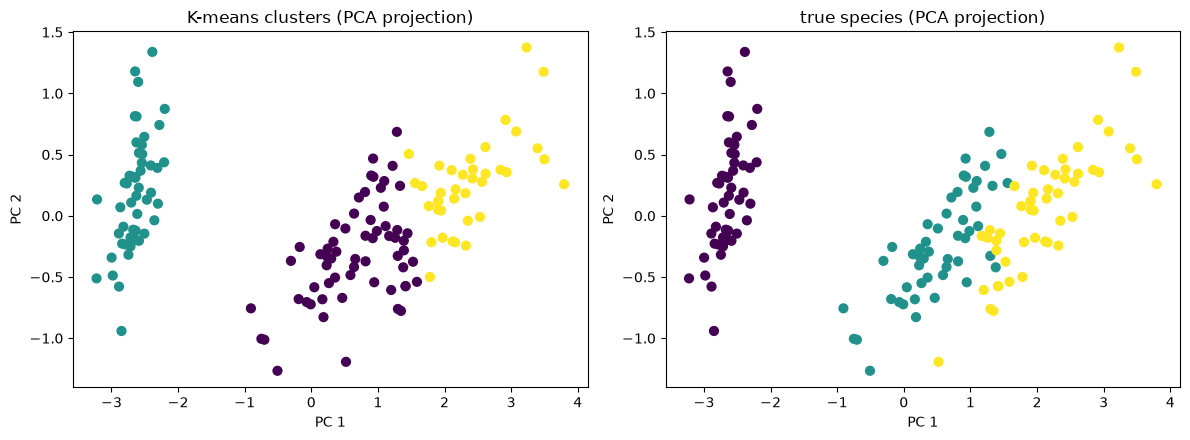

In [48]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

kmeans_iris = KMeans(n_clusters=3, random_state=2024, n_init=10).fit(X_iris)
labels_iris = kmeans_iris.labels_

print(f"Silhouette Score    : {silhouette_score(X_iris, labels_iris):.3f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_iris, labels_iris):.3f}")
print(f"Adjusted Rand Index : {adjusted_rand_score(y_iris, labels_iris):.3f}")
print("contingency (rows = true species, columns = cluster):")
display(pd.crosstab(pd.Series(iris.target_names[y_iris], name="species"), pd.Series(labels_iris, name="cluster")))

pcs = PCA(n_components=2).fit_transform(X_iris)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(pcs[:, 0], pcs[:, 1], c=labels_iris, cmap="viridis", s=40); ax[0].set_title("K-means clusters (PCA projection)")
ax[1].scatter(pcs[:, 0], pcs[:, 1], c=y_iris, cmap="viridis", s=40); ax[1].set_title("true species (PCA projection)")
for a in ax: a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()

K-means recovers *setosa* perfectly (all 50 in cluster 1) but mixes the other two species: 14 virginica flowers fall in the versicolor cluster and 2 versicolor in the virginica one — ARI **0.730**, silhouette 0.553, Davies-Bouldin 0.662 (*k* = 3, `n_init=10`). The labels were never used for fitting; the PCA view shows why: versicolor and virginica overlap, and no distance-based method can separate what overlaps.

### Exercise 2: Comparing DBSCAN and K-means on moon data
Steps (book): load the libraries, create and scale the dataset, apply `KMeans` and `DBSCAN`, visualise the results.

,clusters,noise,ARI
eps (scaled data),,,
0.2,8,26,0.380
0.3,2,6,0.948
0.4,1,1,0.000


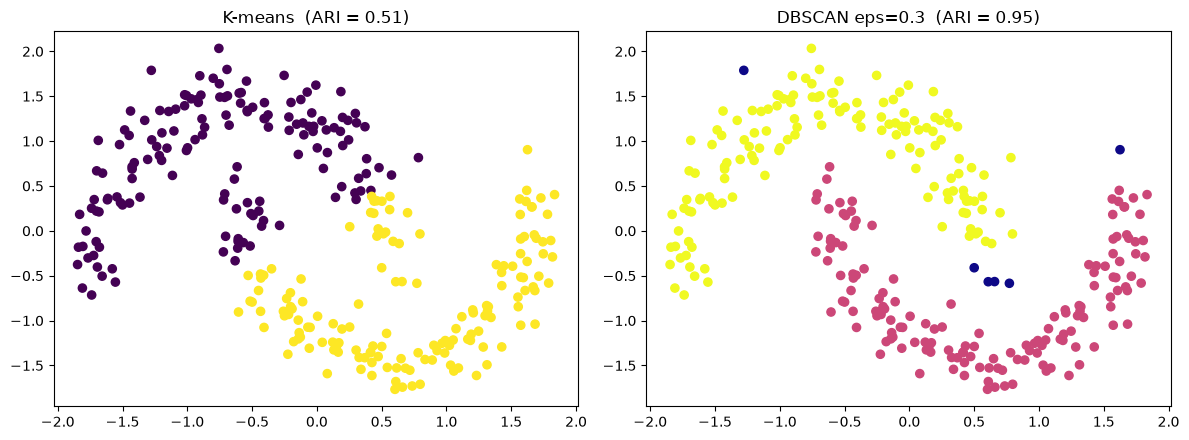

In [49]:
X_mo, y_mo = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_mo = StandardScaler().fit_transform(X_mo)

km_lab = KMeans(n_clusters=2, random_state=2024, n_init=10).fit_predict(X_mo)
rows = []
for eps in [0.2, 0.3, 0.4]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X_mo)
    rows.append({"eps (scaled data)": eps, "clusters": len(set(lab)) - (1 if -1 in lab else 0), "noise": int((lab == -1).sum()), "ARI": adjusted_rand_score(y_mo, lab)})
display(pd.DataFrame(rows).set_index("eps (scaled data)").round(3))

db_lab = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_mo)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(X_mo[:, 0], X_mo[:, 1], c=km_lab, cmap="viridis", s=35); ax[0].set_title(f"K-means  (ARI = {adjusted_rand_score(y_mo, km_lab):.2f})")
ax[1].scatter(X_mo[:, 0], X_mo[:, 1], c=db_lab, cmap="plasma", s=35); ax[1].set_title(f"DBSCAN eps=0.3  (ARI = {adjusted_rand_score(y_mo, db_lab):.2f})")
plt.tight_layout(); plt.show()

The book's `eps=0.2` was chosen for the *unscaled* moons; standardising changes the geometry, so `eps` has to be re-chosen: `eps=0.2` → 8 clusters and 26 noise points (ARI 0.38), **`eps=0.3` → 2 clusters, 6 noise points, ARI 0.95**, `eps=0.4` → a single cluster (ARI 0.00). K-means (`n_init=10`) gets ARI 0.51. The book's claim that DBSCAN outperforms K-means on non-convex data holds — but only with a sensible `eps`: a K-means result is stable, a DBSCAN result is a function of `eps`.

### Exercise 3: Clustering high-dimensional data with PCA and GMMs
Steps (book): load and preprocess the dataset, apply PCA for dimensionality reduction, fit the GMM, visualise the clustered output. The book does not name a dataset; the 64-dimensional **digits** dataset (1,797 handwritten digit images, 10 classes) is used.

digits: (1797, 64) -> PCA: (1797, 31) (90.0% of the variance)


ARI vs the true digits -> GMM: 0.493 | K-means: 0.475
NMI vs the true digits -> GMM: 0.649 | K-means: 0.629
mean largest membership probability: 0.999 | points with probability < 0.9: 4 of 1797


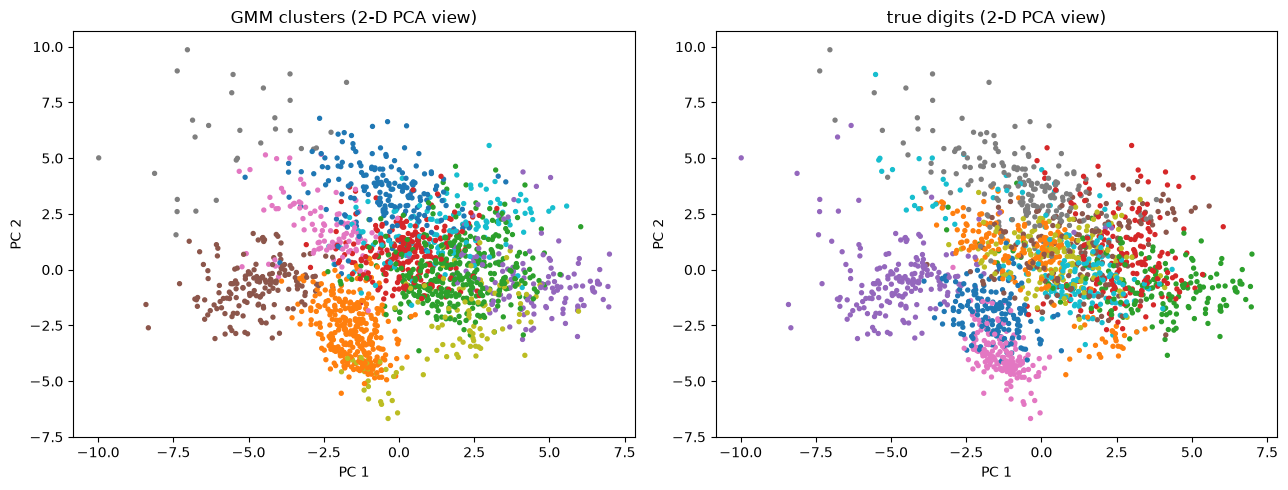

GMM cluster,0,1,2,3,4,5,6,7,8,9
true digit,,,,,,,,,,
0,0,175,1,0,0,0,0,0,0,2
1,0,0,0,94,0,0,60,0,27,1
2,1,0,0,12,110,0,4,0,50,0
3,6,0,157,11,5,0,0,0,2,2
4,9,0,0,0,0,155,7,9,0,1
5,0,1,59,3,0,1,0,0,0,118
6,0,146,0,2,0,0,1,0,32,0
7,151,0,0,0,8,0,3,17,0,0
8,2,0,23,120,10,0,10,0,2,7


In [50]:
from sklearn.datasets import load_digits

Xd, yd = load_digits(return_X_y=True)
Xd = StandardScaler().fit_transform(Xd)

pca = PCA(n_components=0.90, random_state=0).fit(Xd)           # keep 90% of the variance
Xp = pca.transform(Xd)
print("digits:", Xd.shape, "-> PCA:", Xp.shape, f"({pca.explained_variance_ratio_.sum():.1%} of the variance)")

gmm_d = GaussianMixture(n_components=10, random_state=2024).fit(Xp)
lab_gmm = gmm_d.predict(Xp)
lab_km = KMeans(n_clusters=10, n_init=10, random_state=2024).fit_predict(Xp)
print("ARI vs the true digits -> GMM:", round(adjusted_rand_score(yd, lab_gmm), 3), "| K-means:", round(adjusted_rand_score(yd, lab_km), 3))
print("NMI vs the true digits -> GMM:", round(normalized_mutual_info_score(yd, lab_gmm), 3), "| K-means:", round(normalized_mutual_info_score(yd, lab_km), 3))

conf = gmm_d.predict_proba(Xp).max(axis=1)
print(f"mean largest membership probability: {conf.mean():.3f} | points with probability < 0.9: {(conf < 0.9).sum()} of {len(conf)}")

p2 = PCA(n_components=2, random_state=0).fit_transform(Xd)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sc = ax[0].scatter(p2[:, 0], p2[:, 1], c=lab_gmm, cmap="tab10", s=8); ax[0].set_title("GMM clusters (2-D PCA view)")
ax[1].scatter(p2[:, 0], p2[:, 1], c=yd, cmap="tab10", s=8); ax[1].set_title("true digits (2-D PCA view)")
for a in ax: a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()
display(pd.crosstab(pd.Series(yd, name="true digit"), pd.Series(lab_gmm, name="GMM cluster")))

PCA keeps 31 of the 64 components for 90% of the variance. The GMM reaches ARI **0.493** (NMI 0.649) against K-means' 0.475 (0.629): roughly equal. The contingency table shows some clean clusters (digit 0 → cluster 1, digit 4 → cluster 5, digit 7 → cluster 0, each ≈ 150–175 images) and several confusions: digits 3 and 9 (and part of 5) share cluster 2, digits 1 and 8 share cluster 3, digit 5 is split between clusters 2 and 9 and digit 2 between clusters 4 and 8. The PCA scatter shows the same picture — a few well-separated digits and a large overlapping centre.
The mean largest membership probability is **0.999** (only 4 of 1,797 points are below 0.9) although many clusters do not align with the digits: the GMM is extremely **over-confident** when its Gaussian assumption is only approximate — the book's warning is right, but the remedy is not `CalibratedClassifierCV` (see above).

In [51]:
rows = []
for ct in ["full", "tied", "diag", "spherical"]:
    g = GaussianMixture(n_components=10, covariance_type=ct, random_state=2024).fit(Xp)
    rows.append({"covariance_type": ct, "ARI vs digits": adjusted_rand_score(yd, g.predict(Xp)), "BIC": g.bic(Xp)})
display(pd.DataFrame(rows).set_index("covariance_type").round(3))
bic_k = {k: GaussianMixture(n_components=k, random_state=2024).fit(Xp).bic(Xp) for k in [6, 8, 10, 12, 14]}
print("BIC by number of components (full covariance):", {k: round(v) for k, v in bic_k.items()})

,ARI vs digits,BIC
covariance_type,,
full,0.493,91588.298
tied,0.542,164908.062
diag,0.506,149837.234
spherical,0.457,160078.222


BIC by number of components (full covariance): {6: 89588, 8: 91225, 10: 91588, 12: 90746, 14: 96168}


The covariance type changes the answer: `tied` (one shared covariance) has the best ARI (0.542) but by far the worst BIC (164,908 against 91,588 for `full`) — BIC and ARI disagree again. Across the number of components BIC is lowest at 6 (89,588), then 12 (90,746), not at the true 10 (91,588). Likelihood-based criteria select the model that best describes the *density*, not the one aligned with an unknown labelling.

## Chapter takeaways
1. **Clustering is built on distance, so scale first.** Re-expressing one feature in different units dropped K-means' ARI from 0.81 to 0.50; standardising restored it.
2. **K-means** = Lloyd's alternation (verified by hand to give identical labels, centroids and inertia). It finds a *local* optimum: with one random start only 1 of 8 seeds was good, K-means++ 6 of 8, best-of-10 7 of 8 — always use K-means++ and `n_init`.
3. **Choosing *k* is not mechanical.** On blobs generated with 4 centres (two touching pairs), the elbow, silhouette and Davies-Bouldin say 2, Calinski-Harabasz says 3, BIC (GMM) says 3, and only the ARI (needs labels) says 4. The book's "two to three" is what the internal criteria show — not the generating process.
4. **Hierarchical clustering:** Ward behaves like K-means; single/average linkage chain and create one-point clusters; the dendrogram's merge heights are a visual *k* selector; the O(n²) distance matrix limits it to thousands of points (≈ 2 s at 8,000 points vs ≈ 0.01 s for K-means).
5. **DBSCAN** finds arbitrary shapes and noise but only in a narrow `eps` window (works at 0.2, merges the crescents at ≥ 0.25, shatters at ≤ 0.15) and `eps` must be re-chosen when the scaling changes; the k-distance elbow points to the window.
6. **Internal metrics prefer convex clusters:** silhouette/Davies-Bouldin scored K-means' wrong moons better than DBSCAN's correct ones (ARI 0.24 vs 0.96). Compare like with like and look at the data.
7. **Choosing an algorithm** (measured): only DBSCAN recovers moons and circles; K-means/Ward fail on both; with overlapping blobs nobody wins; in high dimensions distances concentrate (relative contrast 765 → 0.17 from 2 to 1,000 d), so reduce dimension first.
8. **Spectral clustering** follows non-convex shapes (ARI 1.0 on moons) but needs a graph and an eigen-decomposition; **GMMs** give soft assignments and a likelihood (BIC) but are over-confident when the Gaussian assumption is wrong (mean confidence 0.999 on digits with ARI 0.49), and `CalibratedClassifierCV` cannot repair them.

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Elbow method | "two to three clusters are the optimal choices" on 4-centre data | the blobs are two touching pairs: elbow/silhouette/Davies-Bouldin → 2, Calinski-Harabasz → 3, only ARI (needs labels) → 4; on a linear axis the 2 → 4 drop is invisible |
| K-means description | "randomly creates centroids … positioned approximately within the average distance" | the default init is K-means++; a centroid is exactly the **mean** of its points; the result is a local optimum (`n_init`) |
| Metric recipe data | evaluation recipe silently switches to *unscaled* blobs | its numbers (0.534 / 0.702 / 0.814) differ from the scaled data of the K-means recipe (0.531 / 0.727 / 0.801) |
| Silhouette range | "−1 (poor clustering)" | a negative value means a point is probably in the *wrong* cluster; the score is per-point |
| k-distance plot | y-axis "5th nearest neighbor distance" | column 0 is the point itself, so it is the 4th *other* neighbour — consistent with `min_samples` counting the point itself |
| DBSCAN `eps=0.2` | presented as the setting | valid only for the unscaled moons; after standardising it gives 8 clusters (ARI 0.38), `eps=0.3` works, `eps=0.4` gives one cluster |
| `make_ circles` | in the import list | stray space — a `SyntaxError` if copied |
| Blobs "ideal for K-means or hierarchical" | Fig. 10.8 description | with this seed two of the three blobs overlap; all three algorithms score ARI ≤ 0.62 |
| Spectral clustering | "works well on large datasets with many features" | needs a graph and an eigen-decomposition; the default RBF affinity is a dense n × n matrix (≈ 50–180× slower than K-means at ≤ 4,000 points); only conditionally true |
| Spectral warning | not mentioned | scikit-learn 1.9.1 warns "Graph is not fully connected" for the default `n_neighbors=10` on the moons (harmless; `n_neighbors=15` removes it) |
| GMM probabilities | "review `CalibratedClassifierCV`" | it needs a supervised classifier: `AttributeError: 'GaussianMixture' object has no attribute 'classes_'` |
| True labels | discarded (`_`) throughout | kept here to score clusterings with ARI |

*Chapters 1–10 are complete.*